# ME249 Fall 2026 - Project 2 - Extra Task ET2
**Genetic algorithm fit of the inverse relation  (Tw - Tsat) = nh1 q"^nh2 (g + nh4 gen gamma)^nh3 P^nh5  (ET2.1)**

* Cell 1: CodeP2.1F26 data of Task 2.3 (77 points + 15 validation points).
* Cell 2: reorganisation of the data: q", g, gamma, P are inputs, Tw - Tsat is the output.
* Cell 3: copy of the Task 2.3 genetic algorithm (see header).
* Cell 4: figure style (added).
* Cell 5: values implied by Task 2.3, GA fit of (ET2.1), comparison table.
* Cell 6: synthetic-data test of the role of the noise in the data.

In [1]:
'''>>>>> start CodeP2.1F26
    V.P. Carey ME249, Fall 2026
    MODIFIED for Task 2.3 (five-constant model):
      - two data values corrected to match the Appendix listing of the project
        statement: row 0  q" 44.2 -> 44.1 W/cm2,  row 6  superheat 37.8 -> 37.5 C
      - modification (i): the red-text data lines (P = 9.5 and 7.0 kPa, gamma = 0
        and 1.71) are uncommented -> 77 data points
      - modification (ii): ND = NS = 77
      - added: the 15 validation data points of the Appendix are stored in the
        array vdata (used only to check the fitted relation, not for training)'''

# version 3 print function
from __future__ import print_function
# seed the pseudorandom number generator
from random import random
from random import seed
# seed random number generator
seed(1)

#import math and numpy packages
import math
import numpy

%matplotlib inline
# importing the required module
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [10, 8] # for square canvas


#import copy
from copy import copy, deepcopy


#create arrays
ydata = []
lydata = []

#Parameters for Evolution Loop
#set data parameters
ND = 77       #number of data vectors in array
DI = 5        #number of data items in vector
NS = 77       #total number of DNA strands

# j is column, i is row downward for ydata[i][j] - both start at zero
# so it is:  ydata[row][column]
# this is an array that is essentially a list of lists

#assembling data array
#store array where rows are data vectors
#[heat flux, superheat, gravity, surface tension parameter, pressure]

ydata =     [[44.1, 32.5, 0.098, 1.79, 5.5]]    # corrected (was 44.2)
ydata.append([47.4, 33.2, 0.098, 1.79, 5.5])
ydata.append([49.4, 34.2, 0.098, 1.79, 5.5])

ydata.append([59.2, 34.8, 0.098, 1.79, 5.5])
ydata.append([67.8, 36.3, 0.098, 1.79, 5.5])
ydata.append([73.6, 37.3, 0.098, 1.79, 5.5])
ydata.append([76.3, 37.5, 0.098, 1.79, 5.5])     # corrected (was 37.8)
ydata.append([85.3, 39.2, 0.098, 1.79, 5.5])
ydata.append([96.5, 39.3, 0.098, 1.79, 5.5])
ydata.append([111., 42.3, 0.098, 1.79, 5.5])
ydata.append([124., 43.5, 0.098, 1.79, 5.5])
ydata.append([136.2, 45.4, 0.098, 1.79, 5.5])

ydata.append([143.5, 46.7, 0.098, 1.79, 5.5])
ydata.append([154.6, 47.9, 0.098, 1.79, 5.5])
ydata.append([163.1, 48.6, 0.098, 1.79, 5.5])
ydata.append([172.8, 50.9, 0.098, 1.79, 5.5])
ydata.append([184.2, 51.7, 0.098, 1.79, 5.5])
ydata.append([203.7, 56.4, 0.098, 1.79, 5.5])

ydata.append([36.7, 30.2, 9.8, 1.79, 5.5])
ydata.append([55.1, 34.1, 9.8, 1.79, 5.5])
ydata.append([67.5, 35.3, 9.8, 1.79, 5.5])
ydata.append([78.0, 37.8, 9.8, 1.79, 5.5])
ydata.append([92.0, 38.1, 9.8, 1.79, 5.5])
ydata.append([120., 44.1, 9.8, 1.79, 5.5])
ydata.append([134.3, 46.9, 9.8, 1.79, 5.5])
ydata.append([150.3, 48.5, 9.8, 1.79, 5.5])
ydata.append([167., 49.2, 9.8, 1.79, 5.5])
ydata.append([184., 52.7, 9.8, 1.79, 5.5])
ydata.append([196.5, 53.1, 9.8, 1.79, 5.5])

ydata.append([42.4, 28.0, 19.6, 1.79, 9.5])
ydata.append([48.7, 29.3, 19.6, 1.79, 9.5])
ydata.append([54.5, 29.6, 19.6, 1.79, 9.5])

ydata.append([62.1, 28.5, 19.6, 1.79, 9.5])
ydata.append([70.8, 30.5, 19.6, 1.79, 9.5])
ydata.append([73.7, 30.3, 19.6, 1.79, 9.5])
ydata.append([81.8, 30.6, 19.6, 1.79, 9.5])
ydata.append([91.9, 34.5, 19.6, 1.79, 9.5])
ydata.append([103.9, 34.5, 19.6, 1.79, 9.5])
ydata.append([119.1, 35.4, 19.6, 1.79, 9.5])
ydata.append([133.7, 36.8, 19.6, 1.79, 9.5])
ydata.append([139.9, 38.1, 19.6, 1.79, 9.5])
ydata.append([148.3, 39.1, 19.6, 1.79, 9.5])
ydata.append([157.0, 40.0, 19.6, 1.79, 9.5])
ydata.append([169.1, 42.2, 19.6, 1.79, 9.5])
ydata.append([179.2, 43.2, 19.6, 1.79, 9.5])
ydata.append([205.0, 46.0, 19.6, 1.79, 9.5])

ydata.append([42.4, 29.7, 19.6, 1.79, 5.5])
ydata.append([48.7, 31.0, 19.6, 1.79, 5.5])
ydata.append([54.5, 31.2, 19.6, 1.79, 5.5])
ydata.append([70.8, 32.4, 19.6, 1.79, 5.5])
ydata.append([73.7, 31.4, 19.6, 1.79, 5.5])
ydata.append([81.8, 32.5, 19.6, 1.79, 5.5])
ydata.append([91.9, 36.3, 19.6, 1.79, 5.5])
ydata.append([103.9, 36.3, 19.6, 1.79, 5.5])
ydata.append([119.1, 37.2, 19.6, 1.79, 5.5])
ydata.append([133.7, 38.4, 19.6, 1.79, 5.5])
ydata.append([139.9, 39.7, 19.6, 1.79, 5.5])
ydata.append([148.3, 40.9, 19.6, 1.79, 5.5])
ydata.append([157.0, 41.6, 19.6, 1.79, 5.5])
ydata.append([169.1, 43.9, 19.6, 1.79, 5.5])
ydata.append([179.2, 45.0, 19.6, 1.79, 5.5])
ydata.append([205.0, 47.9, 19.6, 1.79, 5.5])

ydata.append([77.0, 41.5, 9.8, 0.00, 7.0])
ydata.append([71.0, 40.5, 9.8, 0.00, 7.0])
ydata.append([66.0, 39.5, 9.8, 0.00, 7.0])
ydata.append([62.0, 38.5, 9.8, 0.00, 7.0])
ydata.append([42.0, 34.0, 9.8, 0.00, 7.0])
ydata.append([60.0, 37.5, 9.8, 0.00, 7.0])
ydata.append([53.0, 37.0, 9.8, 0.00, 7.0])

ydata.append([71.7, 36.4, 0.098, 1.71, 5.5])
ydata.append([81.5, 38.5, 0.098, 1.71, 5.5])
ydata.append([90.7, 39.5, 0.098, 1.71, 5.5])
ydata.append([103.3, 41.6, 0.098, 1.71, 5.5])
ydata.append([117.0, 43.1, 0.098, 1.71, 5.5])
ydata.append([138.6, 45.4, 0.098, 1.71, 5.5])
ydata.append([161.7, 47.9, 0.098, 1.71, 5.5])
ydata.append([207.5, 50.9, 0.098, 1.71, 5.5])

# validation data (Appendix, blue text) - NOT used for training
vdata =     [[50.9, 37.2, 0.098, 1.79, 5.5]]
vdata.append([75.1, 37.7, 0.098, 1.79, 5.5])
vdata.append([99.2, 39.7, 0.098, 1.79, 5.5])
vdata.append([147.7, 47.2, 0.098, 1.79, 5.5])
vdata.append([172.1, 49.7, 9.8, 1.79, 5.5])
vdata.append([49.2, 29.6, 19.6, 1.79, 9.5])
vdata.append([71.6, 30.0, 19.6, 1.79, 9.5])
vdata.append([129.8, 36.4, 19.6, 1.79, 9.5])
vdata.append([173.8, 42.8, 19.6, 1.79, 9.5])
vdata.append([68.7, 32.1, 19.6, 1.79, 5.5])
vdata.append([128.5, 38.0, 19.6, 1.79, 5.5])
vdata.append([69.0, 40.1, 9.8, 0.0, 7.0])
vdata.append([58.2, 37.1, 9.8, 0.0, 7.0])
vdata.append([100.3, 41.2, 0.098, 1.71, 5.5])
vdata.append([156.9, 47.4, 0.098, 1.71, 5.5])
NV = len(vdata)
# print the data array
print ('ydata =', ydata)
print ('number of validation points NV =', NV)
# Task 2.1(a): check of the array size and of a single array element
print ('number of rows =', len(ydata), ' ;  ydata[1][0] =', ydata[1][0], ' ;  ydata[6][1] =', ydata[6][1])


''' need deepcopy to create an array of the same size as ydata,
#   since this array is a list(rows) of lists (column entries)  '''
lydata = deepcopy(ydata)  # create array to store ln of data values


# j is column, i is row downward for ydata[i][j] - both start at zero
# so it is:  ydata[row][column]
#now store log values for data
for j in range(DI):
    for i in range(ND):
        lydata[i][j]=math.log(ydata[i][j]+0.000000000010)

#OK now have stored array of log values for data

#end CodeP2.1F26


ydata = [[44.1, 32.5, 0.098, 1.79, 5.5], [47.4, 33.2, 0.098, 1.79, 5.5], [49.4, 34.2, 0.098, 1.79, 5.5], [59.2, 34.8, 0.098, 1.79, 5.5], [67.8, 36.3, 0.098, 1.79, 5.5], [73.6, 37.3, 0.098, 1.79, 5.5], [76.3, 37.5, 0.098, 1.79, 5.5], [85.3, 39.2, 0.098, 1.79, 5.5], [96.5, 39.3, 0.098, 1.79, 5.5], [111.0, 42.3, 0.098, 1.79, 5.5], [124.0, 43.5, 0.098, 1.79, 5.5], [136.2, 45.4, 0.098, 1.79, 5.5], [143.5, 46.7, 0.098, 1.79, 5.5], [154.6, 47.9, 0.098, 1.79, 5.5], [163.1, 48.6, 0.098, 1.79, 5.5], [172.8, 50.9, 0.098, 1.79, 5.5], [184.2, 51.7, 0.098, 1.79, 5.5], [203.7, 56.4, 0.098, 1.79, 5.5], [36.7, 30.2, 9.8, 1.79, 5.5], [55.1, 34.1, 9.8, 1.79, 5.5], [67.5, 35.3, 9.8, 1.79, 5.5], [78.0, 37.8, 9.8, 1.79, 5.5], [92.0, 38.1, 9.8, 1.79, 5.5], [120.0, 44.1, 9.8, 1.79, 5.5], [134.3, 46.9, 9.8, 1.79, 5.5], [150.3, 48.5, 9.8, 1.79, 5.5], [167.0, 49.2, 9.8, 1.79, 5.5], [184.0, 52.7, 9.8, 1.79, 5.5], [196.5, 53.1, 9.8, 1.79, 5.5], [42.4, 28.0, 19.6, 1.79, 9.5], [48.7, 29.3, 19.6, 1.79, 9.5], [54.5, 2

In [2]:
'''>>>>> Extra Task ET2 - reorganisation of the Task 2.3 data set (77 points + 15 validation points):
   q", g, gamma and P become the inputs and the superheat (Tw - Tsat) becomes the output.
   Each row [q", Tw-Tsat, g, gamma, P] becomes [Tw-Tsat, q", g, gamma, P] and lydata is recomputed,
   so that column 0 (the fitted output) is now ln(Tw-Tsat) and column 1 is ln q".'''
ydata = [[row[1], row[0], row[2], row[3], row[4]] for row in ydata]
vdata = [[row[1], row[0], row[2], row[3], row[4]] for row in vdata]
lydata = deepcopy(ydata)
for j in range(DI):
    for i in range(ND):
        lydata[i][j] = math.log(ydata[i][j] + 0.000000000010)
print('reorganised data: ND =', ND, ' first rows [Tw-Tsat, q", g, gamma, P]:', ydata[:2])


reorganised data: ND = 77  first rows [Tw-Tsat, q", g, gamma, P]: [[32.5, 44.1, 0.098, 1.79, 5.5], [33.2, 47.4, 0.098, 1.79, 5.5]]


In [3]:
'''>>>>> start CodeP2.2F26
    V.P. Carey ME249, Fall 2026
    MODIFIED for Extra Task ET2 - copy of the Task 2.3 program used to fit the inverse relation
        (Tw-Tsat) = nh1 (q")^nh2 (g + nh4 gen gamma)^nh3 P^nh5          (ET2.1)
    Because the data were reorganised as [Tw-Tsat, q", g, gamma, P], the error statements of the
    Task 2.3 program become exactly the error function of (ET2.1):
        ferr,i = -ln(Tw-Tsat)_i + ln nh1 + nh2 ln q"_i + nh3 ln(g_i + nh4 gen gamma_i) + nh5 ln P_i
        aFerr_i = |ferr,i| / |ln(Tw-Tsat)_i|
    so only the comments, the print-out labels and the initial guesses (no defaults, nh3 and nh5
    are negative - the multiplicative mutations keep their sign) were changed.
    In the code below n1 ... n5 stand for nh1 ... nh5.  As in Task 2.2 / 2.3:
      - the evolution loop of the skeleton code is placed, unchanged, inside a
        function run_GA(...) so that it can be re-run for several initial guesses,
        mutation amplitudes, numbers of generations and random seeds
      - the maximum mutation amplitude (0.085 in the skeleton) is now the
        argument MUT (relative amplitude, i.e. +/- MUT*100 %)
      - both random generators (python random and numpy.random) are seeded with
        the argument rseed so that every run is reproducible
      - the history of the population-average constants and of aFerrmeanavgn is
        returned, together with the generation at which aFerrmeanavgn first drops
        below the target value (convergence-speed indicator) and the number of
        survivors nkeep of each generation (selection diagnostic)
      - BUG FIX: the skeleton line "import random" re-binds the name random to the
        module and hides the function random() imported in CodeP2.1F26, so the
        initialisation n1i+0.001*random() raises "TypeError: 'module' object is
        not callable".  The line is replaced by an explicit import of the function.'''
from random import random, seed   # (was: import random)

gen_en = 9.8   # earth-normal gravitational acceleration, m/s2

def run_GA(n1i, n2i, n3i, n4i, n5i, NGEN=6000, MUT=0.09,
           MFRAC=0.5, rseed=1, target=0.03, verbose=True):

    '''INITIALIZING PARAMETERS'''
    seed(rseed)                 # python random  (initial population)
    numpy.random.seed(rseed)    # numpy random   (mating / mutation)
    n = []
    ntemp = []
    gen=[0]
    n1avg = [0.0]
    n2avg = [0.0]
    n3avg = [0.0]
    n4avg = [0.0]
    n5avg = [0.0]
    meanAFerr=[0.0]
    aFerrmeanavgn=[0.0]

    # here the number of data vectors equals the number of DNA strands (or organisms)
    for k in range(NGEN-1):
        gen.append(k+1)   # generation array stores the
        meanAFerr.append(0.0)
        aFerrmeanavgn.append(0.0)
        n1avg.append(0.0)
        n2avg.append(0.0)
        n3avg.append(0.0)
        n4avg.append(0.0)
        n5avg.append(0.0)

    '''guesses for initial solution population: n0i = -1 (fixed), n1i ... n5i are arguments'''
    n0i =  -1.0

    #i initialize array where rows are dna vectors [n0i,n1i,...n5i] with random pertubations
    n =  [[-1., n1i+0.001*random(), n2i+0.1*random(), n3i+0.0001*random(), n4i+0.0001*random(), n5i+0.0001*random()]]
    for i in range(ND):
        n.append([-1., n1i+0.0001*random(), n2i+0.001*random(), n3i+0.0001*random(), n4i+0.0001*random(), n5i+0.0001*random()])

    # store also in wtemp
    ntemp = deepcopy(n)

    #define arrays of Ferr (error) functions
    Ferr =  [[0.0]]
    Ferravgn =  [[0.0]]
    aFerr =  [[0.0]]
    aFerravgn =  [[0.0]]
    for i in range(ND-1):
        Ferr.append([0.0])
        aFerr.append([0.0])
        Ferravgn.append([0.0])
        aFerravgn.append([0.0])

    aFerrmeanavgnMin=1000000000.0
    # these store the  n values for minimum population average error durng NGEN generations
    n1min = 0.0
    n2min = 0.0
    n3min = 0.0
    n4min = 0.0
    n5min = 0.0
    kmin = 0
    aFerrta = 0.0
    # these store the time averaged n values durng from generation 800 to NGEN generations
    n1ta = 0.0
    n2ta = 0.0
    n3ta = 0.0
    n4ta = 0.0
    n5ta = 0.0
    kconv = -1      # first generation with aFerrmeanavgn < target (-1 = never)
    nkeephist = []  # (added) number of survivors nkeep at each generation

    '''START OF EVOLUTION LOOP'''
    for k in range(NGEN):

        '''CALCULATING ERROR (FITNESS) - Eq. (1.3): organism i is paired with data point i'''
        for i in range(ND):

            # (ET2.1): -ln(Tw-Tsat) + ln nh1 + nh2 ln q" + nh3 ln(g + nh4 gen gamma) + nh5 ln P
            Ferr[i] = n[i][0]*lydata[i][0] + math.log(n[i][1]) + n[i][2]*lydata[i][1]
            Ferr[i] = Ferr[i] + n[i][3]*math.log( ydata[i][2] + n[i][4]*gen_en*ydata[i][3] ) + n[i][5]*lydata[i][4]

            aFerr[i] = abs(Ferr[i])/abs(lydata[i][0])  #- absolute fractional error
        #-------------
        aFerrmean = numpy.mean(aFerr) #mean error for population for this generation
        meanAFerr[k]=aFerrmean  #store aFerrmean for this generation gen[k]=k
        aFerrmedian = numpy.median(aFerr) #median error for population for this generation

        '''SELECTION'''
        clim = MFRAC*aFerrmedian  #cut off limit is a fraction/multiplier MFRAC of median value for population
        nkeep = 0
        for j in range(NS):  # NS Ferr values, one for each solution in population
            if (aFerr[j] < clim):
                nkeep = nkeep + 1
                #ntemp[nkeep][0] = n[j][0] = -1 so it is unchanged;
                ntemp[nkeep-1][1] = n[j][1];
                ntemp[nkeep-1][2] = n[j][2];
                ntemp[nkeep-1][3] = n[j][3];
                ntemp[nkeep-1][4] = n[j][4];
                ntemp[nkeep-1][5] = n[j][5];
        #compute number to be added by mating
        nnew = NS - nkeep
        nkeephist.append(nkeep)   # (added) number of survivors, diagnostic of selection pressure

        '''MATING'''
        for j in range(nnew):
            # pick two survivors randomly
            nmate1 = numpy.random.randint(low=0, high=nkeep+1)
            nmate2 = numpy.random.randint(low=0, high=nkeep+1)

            '''here, do not change property ntemp[nkeep+j+1][0], it's always fixed at the value -1'''
            if (numpy.random.rand() < 0.5):
                ntemp[nkeep+j+1][1] = n[nmate1][1]*(1.+MUT*2.*(0.5-numpy.random.rand()))  # property 1, mutation added
            else:
                ntemp[nkeep+j+1][1] = n[nmate2][1]*(1.+MUT*2.*(0.5-numpy.random.rand()))

            if (numpy.random.rand() < 0.5):
                ntemp[nkeep+j+1][2] = n[nmate1][2]*(1.+MUT*2.*(0.5-numpy.random.rand()))  # property 2, mutation added
            else:
                ntemp[nkeep+j+1][2] = n[nmate2][2]*(1.+MUT*2.*(0.5-numpy.random.rand()))

            if (numpy.random.rand() < 0.5):
                ntemp[nkeep+j+1][3] = n[nmate1][3]*(1.+MUT*2.*(0.5-numpy.random.rand()))  # property 3, mutation added
            else:
                ntemp[nkeep+j+1][3] = n[nmate2][3]*(1.+MUT*2.*(0.5-numpy.random.rand()))

            if (numpy.random.rand() < 0.5):
                ntemp[nkeep+j+1][4] = n[nmate1][4]*(1.+MUT*2.*(0.5-numpy.random.rand()))  # property 4, mutation added
            else:
                ntemp[nkeep+j+1][4] = n[nmate2][4]*(1.+MUT*2.*(0.5-numpy.random.rand()))

            if (numpy.random.rand() < 0.5):
                ntemp[nkeep+j+1][5] = n[nmate1][5]*(1.+MUT*2.*(0.5-numpy.random.rand()))  # property 5, mutation added
            else:
                ntemp[nkeep+j+1][5] = n[nmate2][5]*(1.+MUT*2.*(0.5-numpy.random.rand()))
        #=============================================
        n = deepcopy(ntemp)   # save ntemp as n for use in next generation (next iteration)

        '''AVERAGING OVER POPULATION AND OVER TIME, FINDING MINIMUM ERROR SET OF n VALUES'''
        n1avg[k] = 0.0;
        n2avg[k] = 0.0;
        n3avg[k] = 0.0;
        n4avg[k] = 0.0;
        n5avg[k] = 0.0;
        for j in range(NS):
            n1avg[k] = n1avg[k] + n[j][1]/NS;
            n2avg[k] = n2avg[k] + n[j][2]/NS;
            n3avg[k] = n3avg[k] + n[j][3]/NS;
            n4avg[k] = n4avg[k] + n[j][4]/NS;
            n5avg[k] = n5avg[k] + n[j][5]/NS;

        ''' CALCULATING MEAN ERROR FOR POPULATION (population-average constants vs all data)'''
        for i in range(ND):
            Ferravgn[i] = -1.*lydata[i][0] + math.log(n1avg[k]) + n2avg[k]*lydata[i][1]
            Ferravgn[i] = Ferravgn[i] + n3avg[k]*math.log( ydata[i][2] + n4avg[k]*gen_en*ydata[i][3] ) + n5avg[k]*lydata[i][4]

            aFerravgn[i] = abs(Ferravgn[i])/abs(lydata[i][0])
        #-------------
        aFerrmeanavgn[k] = numpy.mean(aFerravgn)
        if (kconv < 0 and aFerrmeanavgn[k] < target):
            kconv = k

        # time average of n values in population for generations k > 800
        aFerrta = aFerrta + aFerrmeanavgn[k]/NGEN
        if (k > 800):
            n1ta = n1ta + n1avg[k]/(NGEN-800)
            n2ta = n2ta + n2avg[k]/(NGEN-800)
            n3ta = n3ta + n3avg[k]/(NGEN-800)
            n4ta = n4ta + n4avg[k]/(NGEN-800)
            n5ta = n5ta + n5avg[k]/(NGEN-800)

        # save minimum population-average error and corresponding n(i) values
        if (aFerrmeanavgn[k] < aFerrmeanavgnMin):
            aFerrmeanavgnMin = aFerrmeanavgn[k]
            n1min = n1avg[k]
            n2min = n2avg[k]
            n3min = n3avg[k]
            n4min = n4avg[k]
            n5min = n5avg[k]
            kmin = k
        '''end of evolution loop'''

    if verbose:
        print('ENDING: pop.avg nh1-nh5,aFerrmean:', n1avg[k], n2avg[k], n3avg[k], n4avg[k], n5avg[k], aFerrmeanavgn[k])
        print('MINUMUM:  avg nh1-nh5,aFerrmeanMin:', n1min, n2min, n3min, n4min, n5min, aFerrmeanavgnMin, ' at generation', kmin)
        print('TIME AVG:    avg nh1-nh5,aFerrmean:', n1ta, n2ta, n3ta, n4ta, n5ta, aFerrta)

    return dict(nkeephist=nkeephist, gen=gen, n1avg=n1avg, n2avg=n2avg, n3avg=n3avg, n4avg=n4avg, n5avg=n5avg,
                aFerrmeanavgn=aFerrmeanavgn,
                n1min=n1min, n2min=n2min, n3min=n3min, n4min=n4min, n5min=n5min,
                aFerrmeanavgnMin=aFerrmeanavgnMin, kmin=kmin, kconv=kconv,
                n1end=n1avg[k], n2end=n2avg[k], n3end=n3avg[k], n4end=n4avg[k], n5end=n5avg[k],
                aFerrend=aFerrmeanavgn[k], n1ta=n1ta, n2ta=n2ta, n3ta=n3ta, n4ta=n4ta, n5ta=n5ta,
                aFerrta=aFerrta)
# end CodeP2.2F26 (function definition)


In [4]:
'''(added) common figure style for the report figures + output folders'''
import os, json, logging
logging.getLogger('fontTools').setLevel(logging.ERROR)   # silence font-embedding warnings
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap

# categorical colours (fixed order) and single-hue sequential ramp for surfaces
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
MK = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']          # marker shapes = secondary encoding
INK, INK2, GRID = '#0b0b0b', '#52514e', '#dedcd5'
BLUES = LinearSegmentedColormap.from_list('blues', ['#cde2fb', '#86b6ef', '#3987e5', '#256abf', '#184f95', '#0d366b'])

mpl.rcParams.update({
    'font.size': 11, 'axes.titlesize': 11, 'axes.labelsize': 11, 'legend.fontsize': 9.5,
    'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 1.6, 'lines.markersize': 6, 'legend.frameon': False,
    'figure.figsize': [6.4, 4.6], 'savefig.dpi': 200, 'savefig.bbox': 'tight', 'pdf.fonttype': 42})

FIGDIR = '../report/figures/'      # figures used in the LaTeX report
RESDIR = 'results/'                # numerical results (json) used in the report tables
os.makedirs(FIGDIR, exist_ok=True)
os.makedirs(RESDIR, exist_ok=True)

def savefig(name):
    plt.savefig(FIGDIR + name + '.pdf')
    plt.show()

def first_below(hist, thr):
    '''first generation at which a history drops below thr (-1 if never)'''
    for k, v in enumerate(hist):
        if v < thr:
            return k
    return -1

def sci(x, d=2):
    '''LaTeX scientific notation for figure labels, e.g. 1.73 x 10^-3'''
    e = int(math.floor(math.log10(abs(x))))
    return r'%.*f\times10^{%d}' % (d, x / 10**e, e)

def plain_log_ticks(ax, xt=None, yt=None):
    '''plain (non-scientific) tick labels on log axes'''
    from matplotlib.ticker import NullFormatter, NullLocator
    if xt is not None:
        ax.set_xticks(xt); ax.set_xticklabels(['%g' % v for v in xt])
        ax.xaxis.set_minor_locator(NullLocator()); ax.xaxis.set_minor_formatter(NullFormatter())
    if yt is not None:
        ax.set_yticks(yt); ax.set_yticklabels(['%g' % v for v in yt])
        ax.yaxis.set_minor_locator(NullLocator()); ax.yaxis.set_minor_formatter(NullFormatter())

def best_so_far(h):
    return numpy.minimum.accumulate(numpy.array(h))


implied by Task 2.3 GA fit : nh1 = 19.8579  nh2 = 0.33095  nh3 = -0.15287  nh4 = 1.3485  nh5 = -0.17988
[Ferr]mean of (ET2.1) with the implied values: 0.00865


I (implied by Task 2.3)  seed 1 : [Ferr]mean 0.00843 -> 0.00843 -> 0.00843   nh = 20.2740 0.30738 -0.14546 1.3081 -0.14849


I (implied by Task 2.3)  seed 2 : [Ferr]mean 0.00855 -> 0.00854 -> 0.00850   nh = 21.4840 0.30555 -0.14775 1.3235 -0.17101


I (implied by Task 2.3)  seed 3 : [Ferr]mean 0.00850 -> 0.00845 -> 0.00843   nh = 20.5270 0.30781 -0.14593 1.3205 -0.15502


II                       seed 1 : [Ferr]mean 0.01019 -> 0.00962 -> 0.00954   nh = 18.8573 0.28473 -0.10932 1.0978 -0.12293


II                       seed 2 : [Ferr]mean 0.00970 -> 0.00894 -> 0.00869   nh = 18.5184 0.30461 -0.14598 1.2101 -0.09478


II                       seed 3 : [Ferr]mean 0.01079 -> 0.00979 -> 0.00956   nh = 16.7554 0.30243 -0.11950 1.0273 -0.08641


III                      seed 1 : [Ferr]mean 0.01346 -> 0.01324 -> 0.01316   nh = 34.2133 0.29129 -0.21805 1.9605 -0.22415


III                      seed 2 : [Ferr]mean 0.01257 -> 0.01239 -> 0.01223   nh = 31.9183 0.29301 -0.19509 1.7177 -0.24979


III                      seed 3 : [Ferr]mean 0.01245 -> 0.01179 -> 0.01151   nh = 28.7605 0.30615 -0.16918 2.2310 -0.25425
GA runs: 125 s

      | GA (ET2.1)  implied GA  diff %    | exact ET2.1 impl. exact diff %   
nh1   | 20.274      19.858          +2.1  | 20.319      19.016          +6.9
nh2   | 0.30738     0.33095         -7.1  | 0.30769     0.3359          -8.4
nh3   | -0.14546    -0.15287        +4.8  | -0.1445     -0.16148       +10.5
nh4   | 1.3081      1.3485          -3.0  | 1.3305      1.2586          +5.7
nh5   | -0.14849    -0.17988       +17.4  | -0.15139    -0.15815        +4.3
[Ferr]mean of (ET2.1): GA best 0.00843, exact minimum 0.00842, with implied values 0.00865
GA fit of (ET2.1)              train: rms deviation of superheat = 1.778 C, mean |dev|/dT = 0.0306
GA fit of (ET2.1)              valid: rms deviation of superheat = 1.794 C, mean |dev|/dT = 0.0363
Eq. (1.5) solved for Tw-Tsat   train: rms deviation of superheat = 1.672 C, mean |dev|/dT = 0.0313
Eq. (1.5) 

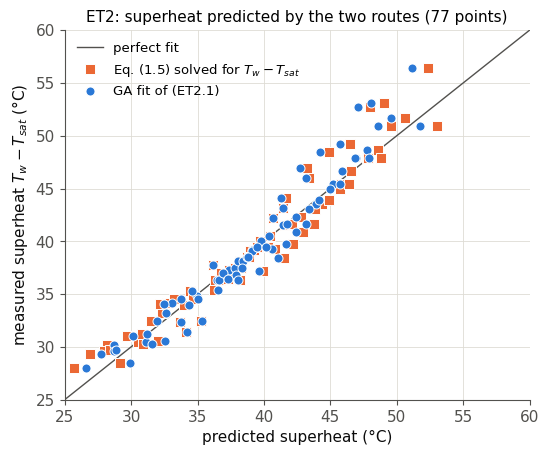

In [5]:
'''ET2 - values implied by the Task 2.3 fit, genetic-algorithm fit of (ET2.1), comparison table.'''
import time
from scipy.optimize import minimize
K5 = lambda r: (r['n1min'], r['n2min'], r['n3min'], r['n4min'], r['n5min'])
b23 = json.load(open(RESDIR + 'task23.json'))
fwd = b23['best']                     # Task 2.3 GA best fit
fref = b23['ref']                     # Task 2.3 deterministic reference minimum

def implied(c):
    '''nh values obtained by solving Eq. (1.5) for (Tw - Tsat)'''
    return dict(n1=c['n1']**(-1. / c['n2']), n2=1. / c['n2'], n3=-c['n3'] / c['n2'], n4=c['n4'], n5=-c['n5'] / c['n2'])
imp = implied(fwd)
print('implied by Task 2.3 GA fit : nh1 = %.4f  nh2 = %.5f  nh3 = %.5f  nh4 = %.4f  nh5 = %.5f' % tuple(imp[k] for k in ['n1', 'n2', 'n3', 'n4', 'n5']))

# generic objective (same as the GA): mean | -ln y + ln c1 + c2 ln x + c3 ln(g + c4 gen gamma) + c5 ln P | / |ln y|
Y = numpy.array(ydata)
def Fgen(c, ly, lx, gg, gam, lP):
    s = gg + c[3] * gen_en * gam
    if c[0] <= 0 or numpy.any(s <= 0):
        return 1e9
    return numpy.mean(numpy.abs(-ly + math.log(c[0]) + c[1] * lx + c[2] * numpy.log(s) + c[4] * lP) / numpy.abs(ly))
lT, lQ, GG, GM, LP = numpy.log(Y[:, 0]), numpy.log(Y[:, 1]), Y[:, 2], Y[:, 3], numpy.log(Y[:, 4])
Finv = lambda c: Fgen(c, lT, lQ, GG, GM, LP)          # inverse relation (ET2.1)
Ffwd = lambda c: Fgen(c, lQ, lT, GG, GM, LP)          # forward relation (1.5)

def fitNM(F, c0):
    '''deterministic multi-start check (Nelder-Mead on [ln c1, c2..c5])'''
    best = None
    for k in range(6):
        x0 = numpy.array([math.log(c0[0]), *c0[1:]]) * (1 + (0.05 * numpy.random.RandomState(k).randn(5) if k else 0))
        rr = minimize(lambda x: F([math.exp(x[0]), *x[1:]]), x0, method='Nelder-Mead',
                      options=dict(xatol=1e-10, fatol=1e-13, maxiter=40000, maxfev=40000))
        if best is None or rr.fun < best.fun:
            best = rr
    return [math.exp(best.x[0]), *best.x[1:]], best.fun

print('[Ferr]mean of (ET2.1) with the implied values: %.5f' % Finv([imp[k] for k in ['n1', 'n2', 'n3', 'n4', 'n5']]))

# genetic algorithm: 3 sets of initial guesses x 3 seeds, then refinement MUT 0.03 -> 0.01
SETSE2 = {'I (implied by Task 2.3)': tuple(imp[k] for k in ['n1', 'n2', 'n3', 'n4', 'n5']),
          'II': (10.0, 0.5, -0.1, 1.0, -0.1),
          'III': (40.0, 0.25, -0.25, 2.0, -0.3)}
t0 = time.time()
seqE2 = []
for name, init in SETSE2.items():
    for s in [1, 2, 3]:
        r = run_GA(*init, NGEN=6000, MUT=0.09, rseed=s, verbose=False)
        x, Fx, Fst = K5(r), r['aFerrmeanavgnMin'], [r['aFerrmeanavgnMin']]
        for st, MUT in enumerate([0.03, 0.01]):
            r2 = run_GA(*x, NGEN=6000, MUT=MUT, rseed=1000 * (st + 1) + s, verbose=False)
            if r2['aFerrmeanavgnMin'] < Fx:
                x, Fx = K5(r2), r2['aFerrmeanavgnMin']
            Fst.append(Fx)
        seqE2.append(dict(set=name, init=init, seed=s, F=Fx, F_stages=Fst, n1=x[0], n2=x[1], n3=x[2], n4=x[3], n5=x[4],
                          F0=r['aFerrmeanavgnMin'], k0=r['kmin']))
        print('%-24s seed %d : [Ferr]mean %s   nh = %.4f %.5f %.5f %.4f %.5f' % (name, s, ' -> '.join('%.5f' % f for f in Fst), *x))
print('GA runs: %.0f s' % (time.time() - t0))
bE2 = min(seqE2, key=lambda d: d['F'])
ga2 = {k: bE2[k] for k in ['n1', 'n2', 'n3', 'n4', 'n5']}

# deterministic references: exact minimum of (ET2.1) and values implied by the exact minimum of (1.5)
cinv, Finv_ref = fitNM(Finv, [ga2[k] for k in ['n1', 'n2', 'n3', 'n4', 'n5']])
inv_ref = dict(zip(['n1', 'n2', 'n3', 'n4', 'n5'], cinv))
imp_ref = implied(fref)

print('\n%-5s | %-11s %-11s %-9s | %-11s %-11s %-9s' % ('', 'GA (ET2.1)', 'implied GA', 'diff %', 'exact ET2.1', 'impl. exact', 'diff %'))
tabE2 = []
for k in ['n1', 'n2', 'n3', 'n4', 'n5']:
    d1 = 100 * (ga2[k] - imp[k]) / abs(imp[k]); d2 = 100 * (inv_ref[k] - imp_ref[k]) / abs(imp_ref[k])
    tabE2.append(dict(k=k, ga=ga2[k], imp=imp[k], diff=d1, inv_ref=inv_ref[k], imp_ref=imp_ref[k], diff_ref=d2))
    print('nh%s   | %-11.5g %-11.5g %+8.1f  | %-11.5g %-11.5g %+8.1f' % (k[1], ga2[k], imp[k], d1, inv_ref[k], imp_ref[k], d2))
print('[Ferr]mean of (ET2.1): GA best %.5f, exact minimum %.5f, with implied values %.5f'
      % (bE2['F'], Finv_ref, Finv([imp[k] for k in ['n1', 'n2', 'n3', 'n4', 'n5']])))

# superheat predicted by the two routes
def dT_inv(c, row):            # row = [Tw-Tsat, q", g, gamma, P]
    return c['n1'] * row[1]**c['n2'] * (row[2] + c['n4'] * gen_en * row[3])**c['n3'] * row[4]**c['n5']
for lab, c in [('GA fit of (ET2.1)', ga2), ('Eq. (1.5) solved for Tw-Tsat', imp)]:
    for D, nm in [(ydata, 'train'), (vdata, 'valid')]:
        p = numpy.array([dT_inv(c, row) for row in D]); m = numpy.array([row[0] for row in D])
        print('%-30s %s: rms deviation of superheat = %.3f C, mean |dev|/dT = %.4f' % (lab, nm, numpy.sqrt(numpy.mean((m - p)**2)), numpy.mean(numpy.abs(m - p) / m)))

fig, ax = plt.subplots(figsize=(6.0, 4.8))
xx = numpy.array([20, 70])
ax.plot(xx, xx, '-', color=INK2, lw=1, label='perfect fit')
ax.plot([dT_inv(imp, row) for row in ydata], [row[0] for row in ydata], 's', color=C[1], ms=6.5, mec='white', mew=0.7, label='Eq. (1.5) solved for $T_w-T_{sat}$')
ax.plot([dT_inv(ga2, row) for row in ydata], [row[0] for row in ydata], 'o', color=C[0], ms=6.5, mec='white', mew=0.7, label='GA fit of (ET2.1)')
ax.set_xlim(25, 60); ax.set_ylim(25, 60)
ax.set_xlabel(r'predicted superheat (°C)'); ax.set_ylabel(r'measured superheat $T_w-T_{sat}$ (°C)')
ax.legend(loc='upper left')
ax.set_title('ET2: superheat predicted by the two routes (77 points)')
savefig('et2_parity')


In [6]:
'''ET2 - is the noise in the data responsible for the differences?  Test with synthetic data generated
   from Eq. (1.5) (Task 2.3 constants) at the 77 measured (q" or Tw-Tsat, g, gamma, P):
   (a) noise-free data  -> the GA fit of (ET2.1) must recover the implied values exactly;
   (b) scatter added to q" (log-normal, same rms as the residuals of the Task 2.3 fit), 30 realisations;
   (c) the same scatter expressed as superheat scatter (sigma/n2 on ln(Tw-Tsat)), 30 realisations.
   For (b) and (c) the forward fit (1.5) and the inverse fit (ET2.1) are both made with the deterministic
   minimiser of the same objectives (much faster than the GA, identical minimum).'''
KEYS = ['n1', 'n2', 'n3', 'n4', 'n5']
cf = [fwd[k] for k in KEYS]
def q_model(c, dT, g, gam, P):
    return c[0] * dT**c[1] * (g + c[3] * gen_en * gam)**c[2] * P**c[4]
qd, dTd = Y[:, 1], Y[:, 0]
res_ln = numpy.log(qd) - numpy.log(q_model(cf, dTd, GG, GM, Y[:, 4]))
sig = float(numpy.sqrt(numpy.mean(res_ln**2)))
print('rms of ln(q"_data/q"_pred) for the Task 2.3 fit: sigma = %.4f' % sig)

# (a) noise-free: superheat computed exactly from Eq. (1.5) at the measured q", g, gamma, P
imp_v = [imp[k] for k in KEYS]
dT_exact = imp_v[0] * qd**imp_v[1] * (GG + imp_v[3] * gen_en * GM)**imp_v[2] * Y[:, 4]**imp_v[4]
ydata_saved, lydata_saved = deepcopy(ydata), deepcopy(lydata)
for i in range(ND):
    ydata[i][0] = float(dT_exact[i]); lydata[i][0] = math.log(dT_exact[i])
start = (15.0, 0.4, -0.2, 1.0, -0.1)                       # deliberately away from the implied values
r = run_GA(*start, NGEN=6000, MUT=0.09, rseed=7, verbose=False)
x, Fx = K5(r), r['aFerrmeanavgnMin']
for st, MUT in enumerate([0.03, 0.01, 0.003]):
    r2 = run_GA(*x, NGEN=6000, MUT=MUT, rseed=70 + st, verbose=False)
    if r2['aFerrmeanavgnMin'] < Fx:
        x, Fx = K5(r2), r2['aFerrmeanavgnMin']
ydata, lydata = ydata_saved, lydata_saved
noisefree = dict(zip(KEYS, x)); noisefree['F'] = Fx
print('(a) noise-free synthetic data, GA fit of (ET2.1): [Ferr]mean = %.2e' % Fx)
for k in KEYS:
    print('    nh%s  GA %.5g   implied %.5g   diff %+.2f %%' % (k[1], noisefree[k], imp[k], 100 * (noisefree[k] - imp[k]) / abs(imp[k])))

# (b) and (c): noisy synthetic data
rsn = numpy.random.RandomState(249)
NREAL = 30
synth = {'b': [], 'c': []}
t0 = time.time()
for case in ['b', 'c']:
    for k in range(NREAL):
        eps = rsn.randn(ND)
        if case == 'b':
            q_s, dT_s = q_model(cf, dTd, GG, GM, Y[:, 4]) * numpy.exp(sig * eps), dTd
        else:
            dT_s = dT_exact * numpy.exp(sig / fwd['n2'] * eps); q_s = qd
        cfw, _ = fitNM(lambda c: Fgen(c, numpy.log(q_s), numpy.log(dT_s), GG, GM, LP), cf)
        civ, _ = fitNM(lambda c: Fgen(c, numpy.log(dT_s), numpy.log(q_s), GG, GM, LP), imp_v)
        im = implied(dict(zip(KEYS, cfw)))
        synth[case].append([100 * (civ[j] - im[KEYS[j]]) / abs(im[KEYS[j]]) for j in range(5)])
    synth[case] = numpy.array(synth[case])
print('synthetic noisy fits: %.0f s' % (time.time() - t0))
print('\npercentage difference  (inverse fit - implied by forward fit) / |implied| :')
print('%-5s | %-16s | %-22s | %-22s' % ('', 'measured data', '(b) noise on q" (30x)', '(c) noise on dT (30x)'))
noise_tab = []
for j, k in enumerate(KEYS):
    row = dict(k=k, data=tabE2[j]['diff_ref'], b_mean=float(synth['b'][:, j].mean()), b_std=float(synth['b'][:, j].std()),
               c_mean=float(synth['c'][:, j].mean()), c_std=float(synth['c'][:, j].std()))
    noise_tab.append(row)
    print('nh%s   | %+8.1f         | %+8.1f +/- %6.1f      | %+8.1f +/- %6.1f' % (k[1], row['data'], row['b_mean'], row['b_std'], row['c_mean'], row['c_std']))

json.dump(dict(implied=imp, implied_ref=imp_ref, ga=ga2, ga_F=bE2['F'], inv_ref=inv_ref, inv_ref_F=Finv_ref, table=tabE2, runs=seqE2,
               noisefree=noisefree, sigma=sig, noise_table=noise_tab, F_implied=Finv(imp_v)),
          open(RESDIR + 'et2.json', 'w'), indent=1)


rms of ln(q"_data/q"_pred) for the Task 2.3 fit: sigma = 0.1258


(a) noise-free synthetic data, GA fit of (ET2.1): [Ferr]mean = 2.71e-06
    nh1  GA 19.856   implied 19.858   diff -0.01 %
    nh2  GA 0.33096   implied 0.33095   diff +0.00 %
    nh3  GA -0.15286   implied -0.15287   diff +0.00 %
    nh4  GA 1.3481   implied 1.3485   diff -0.03 %
    nh5  GA -0.17987   implied -0.17988   diff +0.01 %


synthetic noisy fits: 36 s

percentage difference  (inverse fit - implied by forward fit) / |implied| :
      | measured data    | (b) noise on q" (30x)  | (c) noise on dT (30x) 
nh1   |     +6.9         |     +8.2 +/-    5.1      |     +8.6 +/-    5.2
nh2   |     -8.4         |     -7.1 +/-    2.3      |     -6.5 +/-    2.6
nh3   |    +10.5         |     +1.2 +/-    5.0      |     +3.2 +/-    4.9
nh4   |     +5.7         |     -8.0 +/-    8.5      |     -3.8 +/-    9.4
nh5   |     +4.3         |     +4.0 +/-   10.2      |     +0.1 +/-    9.8
